**5.1 ETAPAS DE REGISTRO DE BIOPOTENCIALES**
**ESQUEMA Y FLUJO DE ADQUISICION**
1. Generacion del biopotencial:  los potenciales bioelectricos se originan a nivel celular como resultado de la actuvudad electroquimica en las membranas de las celulas (ya sean cardiacas como musculares). La despolarizacion y repolarizacion generan potenciales de accion que propagan de forma coordinada (por ejemplo como lo es el impulso electrico que recorre las auriculas y los ventriculos del corazon en un ECG , o como lo puede ser la popagacion electrica hacia las fibras musculares en el EMG)   

2. Conduccion Volumetrica: El cuerpo humano actua como un conductor de volumen pasivo, lo cual permite el paso de potenciales de accion por medio de los tejidos hasta manifestarse en la superficie de la piel

3. Transduccion ( interfaz de la piel con el electrodo): los electrodos de superficie convierten la corriente ionica que fluye a traves del cuerpo en una corriente electrica que puede circular por circuitos electricos para su analisis 

4. Acondicionamiento analogico de la señal : 
 - amplificacion de intrumentacion: debido a que las bioseñales presentan amplitudes reducidas del orden de picovoltios o milivoltios se requiere un amplificador operacional diferencial con alta ganancia para elevar la amplitud de la señal y atenuar  los ruidos 
 - filtrado analogico: se aplican filtros para acotar las frecuencias de interes de una bioseñal y filtros para suprimir interferencias en la señal como lo puede ser de la misma corriente electrica 

5. discretizacion o digitalizacion (ADC): la señal analogica es muestreada y cuantificada por medio de un convertidor analogico a digital llamado ADC el cual esta en un microcontrolador, esto para generar un flujo de datos discretos procesables en un computador 

El ciclo completo de registro de biopotenciales 

AMPLIFICACION -----> FILTRAR ------> DIGITALIZAR 

Los pasos posteriores como lo es el analisis espectral como  la extraccion de indices, analisis estadistico y clasificacion es un proceso que se genera en el equipo por lo cual no se especifica en este punto.

**COMPONENTES GENERALES DE UN EQUIPO DE ADQUISICION** 
1. Electrodos de superficie: son elementos conductivos que hacen contacto con la piel con la finalidad de captar diferenciales de potencial bioelectrico.

2. modulo de reacondicionamiento (shield): es la placa de circuitos especializada ( como el modulo shield EKG - EMG) el cual es encargado de recibir la señal, la acondiciona y la adapta a la red de los datos suministrdos 

3. microcontrolador : es el sistema de procesamiento embebido como en este caso el utilizado (arduino uno ) el cual es equipado con un modulo ADC el cual discretiza la bioseñal en el tiempo de toma 

4. Procesamiento : es el equipo o el computador donde se almacenan se gafican y se analizan de forma digital las bioseñales por medio de un sofware de procesamiento de datos como lo es visual studio code mediante codigo en el lenguaje python

**5.2 FUENTES DE RUIDO EN EL REGISTRO DE BIOIMPEDANCIAS**
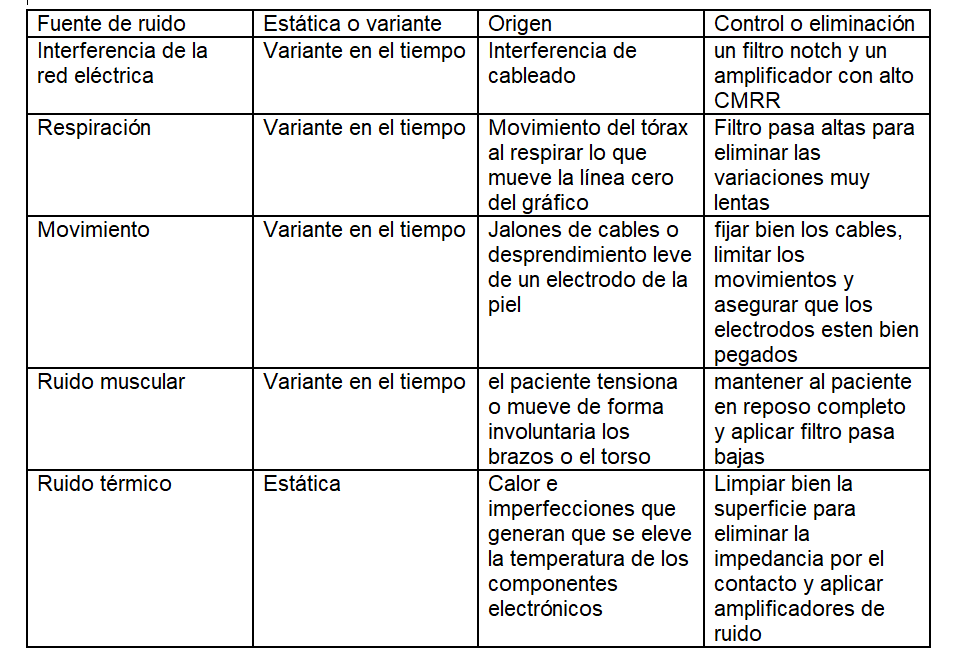

**5.3 PROBLEMATICAS ASOSCIADAS AL ACOPLAMIENTO DEL DIODO**
La capa externa de la piel, esta compuesta por celulas epidermicas muertas y secrecioens lipidicas, lo cual se comporta como una barrera dielectrica con alta impedancia y genera una baja conductividad, aparte de eso la presencia de sudor, aceites , cremas y suciedad en general genera variacioens en la impedancia de la piel y hace que se generen potenciales electroquimicos "parasitos" 
**como optmizar el acoplamiento?**
1. Preparacion de la piel adecuada: Limpiar y frotar suavemente la piel con alcohol para remover grasas, sudor y celulas muertas de la superficie 
2. Asegurar correctamente la posicion de los electrodos asi como su adherencia a la piel con la finalidad deque no se despeguen en el proceso de toma o se posicione en lugares incorrectos 
3. uso de geles conductores: se puede aplicar un electrolito rico en iones como lo puede ser el cloruro de potacia para que oenetre la capa superficual de la piel creando un puente de alta conductividad ionica entre la piel y el sensor metalico 

**¿porque el acoplamiento piel- electrodo es la etapa mas critica de la toma de bioseñales?**
Si la impedancia de contacto es elevada o desbalanceada entre los electrodos de entrada, la capacidad del amplificador de intruementacion para rechazar el ruido en modo comun descrese de forma significativa, lo cual transforma la impedancoa ambiental en un ruido indeseado 
Aparte de ello cualquier distorcion, artefacto de movimiento o inestabilidad introducida en la interfaz  piel - electrodo
se amplificara secuencialmnete en las etapas posteriores a su toma, lo cual imposibilita la recuperacion mediante procesamiento digital de la señal.


**5.4 ANÁLISIS DE LA VARIABILIDAD DE LA FRECUENCIA CARDÍACA (HRV)**

- Detectar los picos R utilizando la función de la librería NeuroKit y de Detectors. ¿Cuál de los algoritmos detecta mejor los picos R?
- Calcular la variabilidad de la frecuencia cardíaca (HRV) a partir de los picos R detectados.
- Implementar la función get_time_domain_features de la librería hrvanalysis para extraer características de HRV en el dominio del tiempo.

**Datos:** ECG_ManuNUEVO1.txt (1000 muestras del ADC de 10 bits). El código de Arduino usa delay(10), es decir un periodo de ≈ 10 ms, por lo que fs ≈ 100 Hz y el registro dura ≈ 10 s.

In [1]:
# Parche de compatibilidad: hrvanalysis busca LombScargle en astropy.stats,
# pero las versiones nuevas de astropy lo tienen en astropy.timeseries
import astropy.stats
from astropy.timeseries import LombScargle
astropy.stats.LombScargle = LombScargle

#%pip install neurokit2 py-ecg-detectors hrv-analysis
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.backends   # evita un error del backend gráfico en algunos entornos
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt
import neurokit2 as nk
from ecgdetectors import Detectors
from hrvanalysis import get_time_domain_features

**Carga de la señal**

In [2]:
#Cargar datos
data = pd.read_csv(r'C:\Users\Lenovo\OneDrive - Universidad de Antioquia\Documentos\2026-2\Bioseñales\Lab\Practica 4\ECG_ManuNUEVO1.txt', header=None)
data.head()

,0
0,513.0
1,514.0
2,512.0
3,511.0
4,511.0


**Acondicionamiento.** La señal se pasa a un arreglo de numpy, se resta la mediana y se aplica un pasa-altas de 0.5 Hz contra la deriva de línea base. No se aplica filtro de 50/60 Hz porque con fs = 100 Hz el límite de Nyquist es 50 Hz. Los complejos QRS apuntan hacia abajo, por lo que la señal se invierte para que los picos R queden hacia arriba.

In [ ]:
fs = 100                          
ecg = data[0].values              
t = np.arange(len(ecg))/fs       

ecg = ecg - np.median(ecg)
sos = butter(2, 0.5, btype="highpass", fs=fs, output="sos")
ecg = -sosfiltfilt(sos, ecg)      # el signo menos invierte la señal

**5.4.1 Detección de picos R: NeuroKit vs Detectors**

Se comparan 5 métodos de NeuroKit y 4 de Detectors (engzee_detector se excluyó porque da error con fs = 100 Hz). Para saber cuál detecta mejor se anotó a mano la posición de los 12 latidos del registro y se midió, para cada método, cuántos de esos latidos encontró (con una tolerancia de ±150 ms = 15 muestras) y el error medio entre el pico detectado y el anotado.

In [ ]:
# Latidos anotados a mano (índices de muestra)
REF = [48, 118, 158, 264, 333, 373, 489, 560, 656, 743, 827, 921]

def evaluar(picos):
    picos = np.array(picos)
    encontrados = 0
    errores = []
    for r in REF:
        distancia = np.min(np.abs(picos - r))      
        if distancia <= 15:                       
            encontrados = encontrados + 1
            errores.append(distancia/fs*1000)     
    return [len(picos), encontrados, np.mean(errores)]

filas = []

# NeuroKit
for metodo in ["neurokit", "pantompkins1985", "hamilton2002", "christov2004", "elgendi2010"]:
    _, info = nk.ecg_peaks(ecg, sampling_rate=fs, method=metodo)
    filas.append(["NeuroKit", metodo] + evaluar(info["ECG_R_Peaks"]))

# Detectors
detectors = Detectors(fs)
filas.append(["Detectors", "pan_tompkins"] + evaluar(detectors.pan_tompkins_detector(ecg)))
filas.append(["Detectors", "hamilton"] + evaluar(detectors.hamilton_detector(ecg)))
filas.append(["Detectors", "christov"] + evaluar(detectors.christov_detector(ecg)))
filas.append(["Detectors", "two_average"] + evaluar(detectors.two_average_detector(ecg)))

tabla = pd.DataFrame(filas, columns=["Librería", "Método", "Detectados", "Encontrados (de 12)", "Error_ms"])
tabla = tabla.sort_values(["Encontrados (de 12)", "Error_ms"], ascending=[False, True]).reset_index(drop=True)
tabla.round(1)

,Librería,Método,Detectados,Encontrados (de 12),Error_ms
0,NeuroKit,neurokit,12,12,5.0
1,NeuroKit,elgendi2010,12,12,13.3
2,NeuroKit,hamilton2002,12,12,44.2
3,Detectors,two_average,12,12,60.8
4,NeuroKit,pantompkins1985,12,12,61.7
5,Detectors,pan_tompkins,12,12,65.8
6,Detectors,hamilton,12,12,66.7
7,NeuroKit,christov2004,12,11,11.8
8,Detectors,christov,12,11,11.8


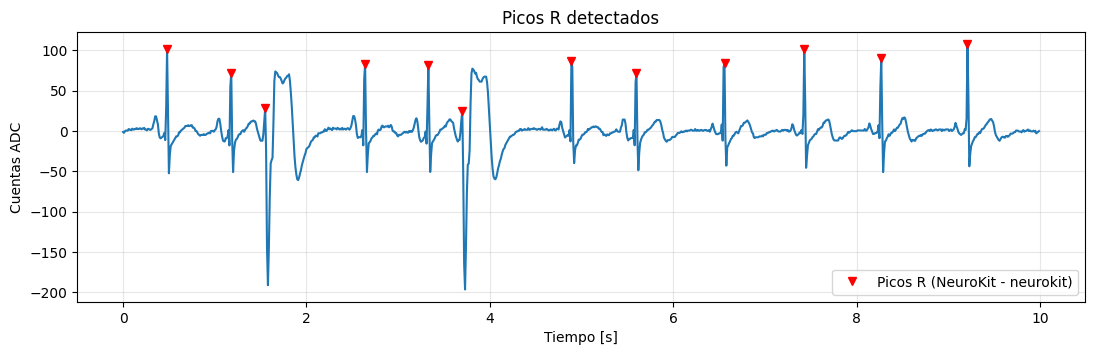

In [5]:
# Picos R del mejor método según la tabla (primera fila: NeuroKit - neurokit)
_, info = nk.ecg_peaks(ecg, sampling_rate=fs, method="neurokit")
picos = info["ECG_R_Peaks"]

plt.figure(figsize=(13,3.5))
plt.plot(t, ecg)
plt.plot(picos/fs, ecg[picos], "rv", label="Picos R (NeuroKit - neurokit)")
plt.title("Picos R detectados")
plt.xlabel("Tiempo [s]")
plt.ylabel("Cuentas ADC")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**5.4.2 Cálculo de la HRV**

Los intervalos RR (ms) son la diferencia entre picos R consecutivos: RR[i] = (pico[i+1] − pico[i]) / fs · 1000.

Intervalos RR [ms]: [ 700  370 1090  690  370 1190  710  960  870  840  940]


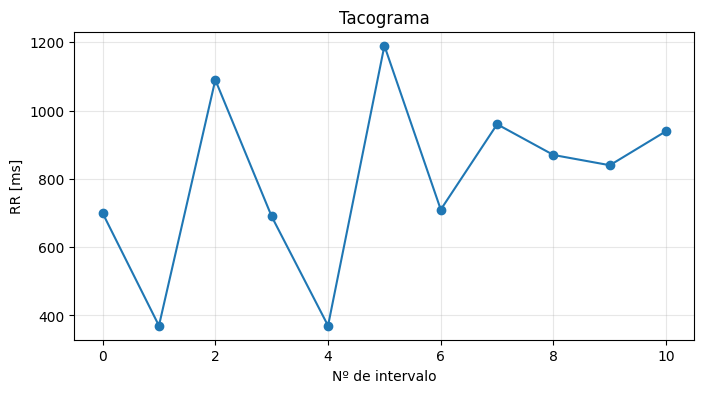

In [6]:
rr = np.diff(picos)/fs*1000      # intervalos RR [ms]
print("Intervalos RR [ms]:", np.round(rr).astype(int))

# Tacograma
plt.figure(figsize=(8,4))
plt.plot(rr, "o-")
plt.title("Tacograma")
plt.xlabel("Nº de intervalo")
plt.ylabel("RR [ms]")
plt.grid(alpha=0.3)
plt.show()

**5.4.3 Características de HRV en el dominio del tiempo (get_time_domain_features)**

La función recibe los intervalos RR en ms y devuelve, entre otras: mean_nni (RR medio), mean_hr (frecuencia cardíaca media), sdnn (desviación estándar de los intervalos, variabilidad total), rmssd (raíz cuadrática media de las diferencias sucesivas, variabilidad latido a latido), nni_50 y pnni_50 (diferencias sucesivas > 50 ms).

In [7]:
hrv = get_time_domain_features(list(rr))
pd.Series(hrv).round(2)

mean_nni      793.64
sdnn          262.19
sdsd          432.23
nni_50          9.00
pnni_50        90.00
nni_20         10.00
pnni_20       100.00
rmssd         432.90
median_nni    840.00
range_nni     820.00
cvsd            0.55
cvnni           0.33
mean_hr        86.70
max_hr        162.16
min_hr         50.42
std_hr         37.38
dtype: float64

**Análisis del 5.4**

Casi todos los métodos de NeuroKit y de Detectors encontraron los 12 latidos. Solo Christov perdió uno y marcó uno falso. Como la mayoría los encontró todos, la diferencia estuvo en el error de localización: el mejor fue el método  de NeuroKit, con = 5 ms. Con solo 12 latidos anotados a mano, esta comparación es orientativa y no demuestra que una librería sea mejor que la otra.

Los valores de HRV son altos (RMSSD = 433 ms y SDNN = 262 ms) porque el registro tiene dos latidos anchos que llegan antes de tiempo: el intervalo RR baja a = 400 ms y la pausa que sigue sube a más de 1000 ms, mientras los latidos normales están en = 700-950 ms. Es un patrón compatible con latidos prematuros, no un diagnóstico, y hace que la variabilidad refleje esos dos latidos más que la variación normal del ritmo. Además, el registro dura solo = 10 s (para HRV de corto plazo se recomiendan 5 min; Task Force, 1996), por lo que los resultados son orientativos.

**5.5 APLICACIONES CLÍNICAS DEL ECG Y DEL EMG**

| Señal | Aplicación clínica | Tipo de registro | Procesamiento |
|---|---|---|---|
| ECG | **Detección y clasificación de arritmias** (por ejemplo, fibrilación auricular) | ECG ambulatorio (Holter o parche de una derivación, de horas a días) o ECG de 12 derivaciones en reposo | Filtrado de ruido y línea base, detección de picos R, análisis de intervalos RR e irregularidad, extracción de características o redes neuronales profundas (Hannun et al., 2019) |
| ECG | **Diagnóstico de isquemia e infarto de miocardio** | ECG de 12 derivaciones en reposo y, en ocasiones, de esfuerzo | Filtrado, detección de latidos y puntos fiduciales, medición del desnivel del segmento ST y de la onda T y Q (Thygesen et al., 2019) |
| ECG | **Evaluación de la HRV y de la función autonómica** (estratificación de riesgo) | ECG en reposo de corta duración (≈ 5 min) o de larga duración (24 h) | Detección de R, depuración de latidos ectópicos, métricas en el dominio del tiempo (SDNN, RMSSD) y de la frecuencia (LF/HF) (Task Force, 1996) |
| EMG | **Diagnóstico de enfermedades neuromusculares** (neuropatías, miopatías, ELA) | EMG de aguja intramuscular, en reposo y con contracción leve a máxima, junto con estudios de conducción nerviosa | Análisis de potenciales de unidad motora (amplitud, duración, número de fases), actividad espontánea y patrón de reclutamiento (Mills, 2005) |
| EMG | **Control de prótesis mioeléctricas** | sEMG de los músculos residuales del antebrazo o del muñón | Filtrado y rectificación, ventaneo, características (MAV, RMS, longitud de onda, cruces por cero) y clasificador de movimientos (Farina et al., 2014) |
| EMG | **Evaluación de fatiga muscular, ergonomía y rehabilitación** | sEMG durante contracciones sostenidas o dinámicas | Amplitud RMS y análisis espectral en el tiempo (la frecuencia mediana disminuye con la fatiga) (Cifrek et al., 2009) |

**5.6 CONCLUSIONES**

1. Las bioseñales tienen amplitudes de microvoltios a milivoltios, por lo que la interfaz piel-electrodo y el control de las fuentes de ruido (red eléctrica, movimiento, deriva de línea base) condicionan todo el procesamiento posterior. Una impedancia de contacto alta o desbalanceada reduce el rechazo de modo común del amplificador y deja pasar la interferencia, y lo que entra contaminado no se recupera por completo con filtrado digital. Por eso la preparación de la piel y la fijación de los electrodos son tan importantes como el análisis posterior.

2. La frecuencia de muestreo (aprox 100 Hz) y la corta duración del registro (aprox 10 s) restringen el análisis de HRV: cada pico R tiene una incertidumbre de ±10 ms, comparable con los valores pequeños de RMSSD, y con aprox 12 latidos las métricas son orientativas. Los estándares clínicos recomiendan al menos 5 min de registro, y una frecuencia de muestreo más alta con temporizador de hardware permitiría localizar mejor los picos.

3. Los complejos anchos que llegan antes de tiempo, seguidos de una pausa más larga, inflan métricas como sdnn y rmssd, de modo que la variabilidad de la serie cruda refleja esos latidos y no la modulación sinusal. Por eso conviene depurar los latidos ectópicos antes de interpretar la HRV, sobre todo cuando hay pocos latidos.

4. La comparación entre NeuroKit y Detectors, se hizo contra una referencia anotada a mano y con métricas cuantitativas (sensibilidad, VPP, F1 y error de localización), y no solo por inspección visual. El mejor desempeño lo obtuvo el método neurokit de NeuroKit sobre la señal invertida, que detectó los 12 latidos sin falsos positivos y con menor error de localización (aprox 5 ms). Como se basa en solo 12 latidos, el resultado es netamente ilustrativo y no permite generalizar que un algoritmo sea mejor que otro.

**REFERENCIAS**

- Cifrek, M., Medved, V., Tonković, S., & Ostojić, S. (2009). Surface EMG based muscle fatigue evaluation in biomechanics. *Clinical Biomechanics, 24*(4), 327–340. https://doi.org/10.1016/j.clinbiomech.2009.01.010
- Farina, D., Jiang, N., Rehbaum, H., Holobar, A., Graimann, B., Dietl, H., & Aszmann, O. C. (2014). The extraction of neural information from the surface EMG for the control of upper-limb prostheses: Emerging avenues and challenges. *IEEE Transactions on Neural Systems and Rehabilitation Engineering, 22*(4), 797–809.
- Hannun, A. Y., Rajpurkar, P., Haghpanahi, M., et al. (2019). Cardiologist-level arrhythmia detection and classification in ambulatory electrocardiograms using a deep neural network. *Nature Medicine, 25*(1), 65–69.
- Huigen, E., Peper, A., & Grimbergen, C. A. (2002). Investigation into the origin of the noise of surface electrodes. *Medical & Biological Engineering & Computing, 40*, 332–338. https://doi.org/10.1007/BF02344216
- Makowski, D., Pham, T., Lau, Z. J., Brammer, J. C., Lespinasse, F., Pham, H., Schölzel, C., & Chen, S. H. A. (2021). NeuroKit2: A Python toolbox for neurophysiological signal processing. *Behavior Research Methods, 53*(4), 1689–1696. https://doi.org/10.3758/s13428-020-01516-y
- Mills, K. R. (2005). The basics of electromyography. *Journal of Neurology, Neurosurgery & Psychiatry, 76*(Suppl 2), ii32–ii35.
- Pan, J., & Tompkins, W. J. (1985). A real-time QRS detection algorithm. *IEEE Transactions on Biomedical Engineering, 32*(3), 230–236.
- Task Force of the European Society of Cardiology and the North American Society of Pacing and Electrophysiology. (1996). Heart rate variability: Standards of measurement, physiological interpretation, and clinical use. *Circulation, 93*(5), 1043–1065.
- Thygesen, K., Alpert, J. S., Jaffe, A. S., et al. (2019). Fourth universal definition of myocardial infarction (2018). *European Heart Journal, 40*(3), 237–269.
- Webster, J. G. (Ed.). (2009). *Medical instrumentation: Application and design* (4th ed.). John Wiley & Sons.